<a href="https://colab.research.google.com/github/prasad0876/pid/blob/main/AI_Zero_Day_IDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import sys
import pyarrow as pa
import pyarrow.parquet as pq
import pandas as pd
import numpy as np
from pathlib import Path
import tensorflow as tf

# 1. Reproducible seeds
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Print environment details
print("=== Environment Information ===")
print(f"Python Version: {sys.version}")
print(f"Pandas Version: {pd.__version__}")
print(f"PyArrow Version: {pa.__version__}")
print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU Available: {len(gpus) > 0} ({gpus if gpus else 'None'})")
print("==============================\n")

# 3. Locate and scan dataset files
dataset_path = Path("/kaggle/input/cicids2017")
if not dataset_path.exists():
    # Fallback search
    import kagglehub
    print("Path /kaggle/input/cicids2017 not found. Downloading/locating via kagglehub...")
    dataset_path = Path(kagglehub.dataset_download("dhoogla/cicids2017"))

print(f"Target dataset directory: {dataset_path}\n")

parquet_files = sorted(list(dataset_path.glob("**/*.parquet")))
if not parquet_files:
    raise FileNotFoundError(f"No parquet files found in {dataset_path}")

# 4. Programmatic Schema and Label Identification
print("=== Inspecting Parquet Schema and Target Labels ===")
combined_columns = set()
file_manifest = []

for file_path in parquet_files:
    file_size_mb = file_path.stat().st_size / (1024 * 1024)
    print(f"\nProcessing file: {file_path.name} ({file_size_mb:.2f} MB)")

    try:
        # Read metadata only to avoid massive memory footprint
        parquet_file = pq.ParquetFile(file_path)
        schema = parquet_file.schema.to_arrow_schema()
        num_rows = parquet_file.metadata.num_rows

        # Keep track of unique columns
        file_cols = schema.names
        combined_columns.update(file_cols)

        # Read a tiny chunk (first 100 rows) to check unique values in suspicious label columns
        sample_df = parquet_file.read_row_group(0).to_pandas().head(100)

        # Attempt to find the label column programmatically
        label_candidates = [col for col in sample_df.columns if 'label' in col.lower() or 'class' in col.lower()]

        # Read full label column if possible or a sample of unique values safely
        # Note: Since reading the whole column is fast for single targets, we extract unique labels.
        full_labels_table = parquet_file.read(columns=[label_candidates[0]]) if label_candidates else None
        if full_labels_table:
            unique_labels = np.unique(full_labels_table.column(0).to_numpy())
        else:
            unique_labels = ["Unknown"]

        print(f" - Row Count: {num_rows:,}")
        print(f" - Detected Label Candidate: {label_candidates}")
        print(f" - Unique Labels found: {list(unique_labels)}")

        file_manifest.append({
            "filename": file_path.name,
            "rows": num_rows,
            "size_mb": file_size_mb,
            "label_column": label_candidates[0] if label_candidates else None
        })
    except Exception as e:
        print(f" [!] Error parsing {file_path.name}: {str(e)}")

print("\n=== Summary Assessment ===")
print(f"Total discovered Parquet files: {len(file_manifest)}")
print(f"Total features found across all schemas: {len(combined_columns)}")
print("Ready to proceed to Data Preprocessing and Splitting once output is confirmed.")


=== Environment Information ===
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas Version: 2.2.3
PyArrow Version: 23.0.1
TensorFlow Version: 2.21.0
GPU Available: False (None)

Path /kaggle/input/cicids2017 not found. Downloading/locating via kagglehub...


100%|██████████| 227M/227M [00:06<00:00, 38.4MB/s]

Extracting files...


Target dataset directory: /root/.cache/kagglehub/datasets/dhoogla/cicids2017/versions/3

=== Inspecting Parquet Schema and Target Labels ===

Processing file: Benign-Monday-no-metadata.parquet (54.14 MB)
 - Row Count: 458,831
 - Detected Label Candidate: ['Label']
 - Unique Labels found: ['Benign']

Processing file: Botnet-Friday-no-metadata.parquet (18.94 MB)
 - Row Count: 176,038
 - Detected Label Candidate: ['Label']
 - Unique Labels found: ['Benign', 'Bot']

Processing file: Bruteforce-Tuesday-no-metadata.parquet (44.00 MB)
 - Row Count: 389,714
 - Detected Label Candidate: ['Label']
 - Unique Labels found: ['Benign', 'FTP-Patator', 'SSH-Patator']

Processing file: DDoS-Friday-no-metadata.parquet (24.13 MB)
 - Row Count: 221,264
 - Detected Label Candidate: ['Label']
 - Unique Labels found: ['Benign', 'DDoS']

Processing file: DoS-Wednesday-no-metadata.parquet (65.04 MB)
 - Row Count: 584,991
 - Detected Label Candidate: ['Label']
 - Unique Labels found: ['Benign', 'DoS GoldenEye',

In [2]:
import gc
import joblib
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

print("=== Phase B & C: Data Preprocessing, Cleaning & Splitting ===")

# Configure paths and options
DATA_DIR = Path("/kaggle/input/cicids2017")
if not DATA_DIR.exists():
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download("dhoogla/cicids2017"))

files = sorted(list(DATA_DIR.glob("**/*.parquet")))

# Define target withholds and samples
WITHHELD_CLASS = "Bot"
SAMPLE_BENIGN_ROWS = 100000  # Cap benign sample to keep training fast and RAM-friendly
SAMPLE_ATTACK_ROWS = 20000   # Cap known attacks to prevent imbalance skew in metrics

benign_dfs = []
known_attack_dfs = []
withheld_attack_dfs = []

# Load datasets incrementally
for f in files:
    print(f"Reading {f.name}...")
    df = pd.read_parquet(f)

    # Normalize column names by stripping spaces
    df.columns = df.columns.str.strip()

    # Identify target column
    lbl_col = "Label"
    if lbl_col not in df.columns:
        continue

    # Clean infinites and extreme values per file
    for col in df.select_dtypes(include=[np.number]).columns:
        # Replace inf with nan temporarily for imputation later
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)

    # Separate classes
    file_benign = df[df[lbl_col] == 'Benign']
    file_attack = df[df[lbl_col] != 'Benign']

    if len(file_benign) > 0:
        benign_dfs.append(file_benign)

    if len(file_attack) > 0:
        # Check if this contains our withheld class
        withheld_mask = file_attack[lbl_col].str.contains(WITHHELD_CLASS, case=False, na=False)
        if withheld_mask.any():
            withheld_attack_dfs.append(file_attack[withheld_mask])
            # Put rest in known attacks
            if (~withheld_mask).any():
                known_attack_dfs.append(file_attack[~withheld_mask])
        else:
            known_attack_dfs.append(file_attack)

# Combine data
all_benign = pd.concat(benign_dfs, ignore_index=True)
all_known_attacks = pd.concat(known_attack_dfs, ignore_index=True)
all_withheld_attacks = pd.concat(withheld_attack_dfs, ignore_index=True)

del benign_dfs, known_attack_dfs, withheld_attack_dfs
gc.collect()

print(f"Initial combined counts - Benign: {len(all_benign):,}, Known Attacks: {len(all_known_attacks):,}, Withheld ({WITHHELD_CLASS}): {len(all_withheld_attacks):,}")

# Random sampling to balance and respect memory
if len(all_benign) > SAMPLE_BENIGN_ROWS:
    all_benign = all_benign.sample(n=SAMPLE_BENIGN_ROWS, random_state=SEED).reset_index(drop=True)
if len(all_known_attacks) > SAMPLE_ATTACK_ROWS:
    all_known_attacks = all_known_attacks.sample(n=SAMPLE_ATTACK_ROWS, random_state=SEED).reset_index(drop=True)

# Identify non-predictive ID columns or zero variance columns to drop
# (e.g. IPs, timestamps, flow IDs if they existed, or columns with constant values)
non_predictive_cols = ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Timestamp']
drop_cols = [col for col in non_predictive_cols if col in all_benign.columns]

# Also drop columns with zero variance
std_devs = all_benign.select_dtypes(include=[np.number]).std()
constant_cols = std_devs[std_devs == 0].index.tolist()
drop_cols.extend(constant_cols)
drop_cols = list(set(drop_cols))

print(f"Dropping non-predictive/constant columns: {drop_cols}")

# Split Benign data into Train, Val, and Test (Benign-only learning focus)
train_benign_raw, test_benign_temp = train_test_split(all_benign, test_size=0.3, random_state=SEED)
val_benign_raw, test_benign_raw = train_test_split(test_benign_temp, test_size=0.5, random_state=SEED)

# Separate features and labels
feature_cols = [col for col in all_benign.columns if col not in drop_cols and col != 'Label']

print(f"Number of final features for model training: {len(feature_cols)}")

# Extract labels
y_test_benign = test_benign_raw['Label'].values
y_val_benign = val_benign_raw['Label'].values
y_known_attacks = all_known_attacks['Label'].values
y_withheld_attacks = all_withheld_attacks['Label'].values

# Fit preprocessing pipelines strictly on train benign data to prevent leakage
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train_benign = imputer.fit_transform(train_benign_raw[feature_cols])
X_train_benign = scaler.fit_transform(X_train_benign)

X_val_benign = scaler.transform(imputer.transform(val_benign_raw[feature_cols]))
X_test_benign = scaler.transform(imputer.transform(test_benign_raw[feature_cols]))

X_known_attacks = scaler.transform(imputer.transform(all_known_attacks[feature_cols]))
X_withheld_attacks = scaler.transform(imputer.transform(all_withheld_attacks[feature_cols]))

# Save preprocessors for later inference deployment
joblib.dump(imputer, 'imputer.joblib')
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(feature_cols, 'feature_cols.joblib')
print("Preprocessors and feature names saved!")

print(f"\n=== Dataset Splits Created ===")
print(f"X_train_benign (Used for model fit): {X_train_benign.shape}")
print(f"X_val_benign (Used for threshold selection): {X_val_benign.shape}")
print(f"X_test_benign (Normal test baseline): {X_test_benign.shape}")
print(f"X_known_attacks (Experiment A test): {X_known_attacks.shape}")
print(f"X_withheld_attacks (Experiment B zero-day proxy test): {X_withheld_attacks.shape}")


=== Phase B & C: Data Preprocessing, Cleaning & Splitting ===
Reading Benign-Monday-no-metadata.parquet...
Reading Botnet-Friday-no-metadata.parquet...
Reading Bruteforce-Tuesday-no-metadata.parquet...
Reading DDoS-Friday-no-metadata.parquet...
Reading DoS-Wednesday-no-metadata.parquet...
Reading Infiltration-Thursday-no-metadata.parquet...
Reading Portscan-Friday-no-metadata.parquet...
Reading WebAttacks-Thursday-no-metadata.parquet...
Initial combined counts - Benign: 1,977,318, Known Attacks: 335,055, Withheld (Bot): 1,437
Dropping non-predictive/constant columns: ['Bwd Avg Bytes/Bulk', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Bwd PSH Flags', 'Bwd URG Flags', 'Bwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bulk Rate', 'Fwd Avg Packets/Bulk', 'Fwd URG Flags']
Number of final features for model training: 67
Preprocessors and feature names saved!

=== Dataset Splits Created ===
X_train_benign (Used for model fit): (70000, 67)
X_val_benign (Used for threshold selection): (15000, 6

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import numpy as np
import joblib
import json

print("=== Phase D: AI Anomaly Detection Model (Autoencoder) ===")

input_dim = X_train_benign.shape[1]

# 1. Build Autoencoder using Functional API (prevents 'layer has never been called' errors)
inputs = layers.Input(shape=(input_dim,), name="Input_Layer")

# Encoder bottleneck
x = layers.Dense(32, activation='relu', name="Enc_Dense_1")(inputs)
x = layers.BatchNormalization(name="Enc_BN_1")(x)
latent = layers.Dense(16, activation='relu', name="Latent_Bottleneck")(x)
latent_bn = layers.BatchNormalization(name="Enc_BN_2")(latent)

# Decoder reconstruction
y = layers.Dense(32, activation='relu', name="Dec_Dense_1")(latent_bn)
y = layers.BatchNormalization(name="Dec_BN_1")(y)
outputs = layers.Dense(input_dim, activation='linear', name="Output_Reconstruction")(y)

autoencoder = models.Model(inputs=inputs, outputs=outputs, name="Autoencoder")
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

# 2. Early Stopping & Model Training (on Benign traffic only)
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("\nTraining the Autoencoder on Benign traffic...")
history = autoencoder.fit(
    X_train_benign, X_train_benign,
    epochs=30,
    batch_size=256,
    validation_data=(X_val_benign, X_val_benign),
    callbacks=[early_stop],
    verbose=1
)

# Save trained model
autoencoder.save("intrusion_autoencoder.keras")
print("Model saved as 'intrusion_autoencoder.keras'.")

# 3. Calculate Reconstruction Error and Select Anomaly Threshold
print("\nCalculating threshold based on validation benign data...")
val_predictions = autoencoder.predict(X_val_benign)
val_mse = np.mean(np.square(X_val_benign - val_predictions), axis=1)

# Select threshold based on 99th percentile of benign validation errors
threshold = float(np.percentile(val_mse, 99))
print(f"Selected Anomaly Threshold (99th percentile): {threshold:.4f}")

# Save threshold metadata
metadata = {
    "input_dimension": input_dim,
    "anomaly_threshold": threshold,
    "target_false_positive_rate": 0.01
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f)
print("Metadata saved as 'model_metadata.json'.")


=== Phase D: AI Anomaly Detection Model (Autoencoder) ===


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 67)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Enc_Dense_1 (Dense)             │ (None, 32)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Enc_BN_1 (BatchNormalization)   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Bottleneck (Dense)       │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Enc_BN_2 (BatchNormalization)   │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dec_Dense_1 (Dense)             │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dec_BN_1 (BatchNormalization)   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Reconstruction (Dense)   │ (None, 67)             │         2,211 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,779 (22.57 KB)

 Trainable params: 5,619 (21.95 KB)

 Non-trainable params: 160 (640.00 B)


Training the Autoencoder on Benign traffic...
Epoch 1/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.6687 - val_loss: 4.2306
Epoch 2/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4021 - val_loss: 4.0025
Epoch 3/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3434 - val_loss: 3.9268
Epoch 4/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3102 - val_loss: 3.8400
Epoch 5/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2871 - val_loss: 3.6834
Epoch 6/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2714 - val_loss: 3.5480
Epoch 7/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2587 - val_loss: 3.3820
Epoch 8/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2475 - val_loss: 3.3290
Epoch 9/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2376 - val_loss: 3.0599
Epoch 10/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2292 - val_loss: 3.0759
Epoch 11/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2239 - val_loss: 2.9267
Epoch

=== Phase E: Evaluation on Real Model Predictions ===
Inference Latency per flow: 0.1337 ms

--- Experiment A: Known-Category Evaluation ---
False Positive Rate (FPR): 0.0117
Recall / True Positive Rate (TPR): 0.6492
                precision    recall  f1-score   support

 Normal/Benign       0.68      0.99      0.80     15000
Anomaly/Attack       0.99      0.65      0.78     20000

      accuracy                           0.79     35000
     macro avg       0.83      0.82      0.79     35000
  weighted avg       0.85      0.79      0.79     35000


--- Experiment B: Withheld-Category (Botnet) Zero-Day Proxy Evaluation ---
False Positive Rate (FPR): 0.0117
Recall / True Positive Rate (TPR): 0.0285
                            precision    recall  f1-score   support

             Normal/Benign       0.91      0.99      0.95     15000
Withheld Attack (Zero-Day)       0.19      0.03      0.05      1437

                  accuracy                           0.90     16437
                 m

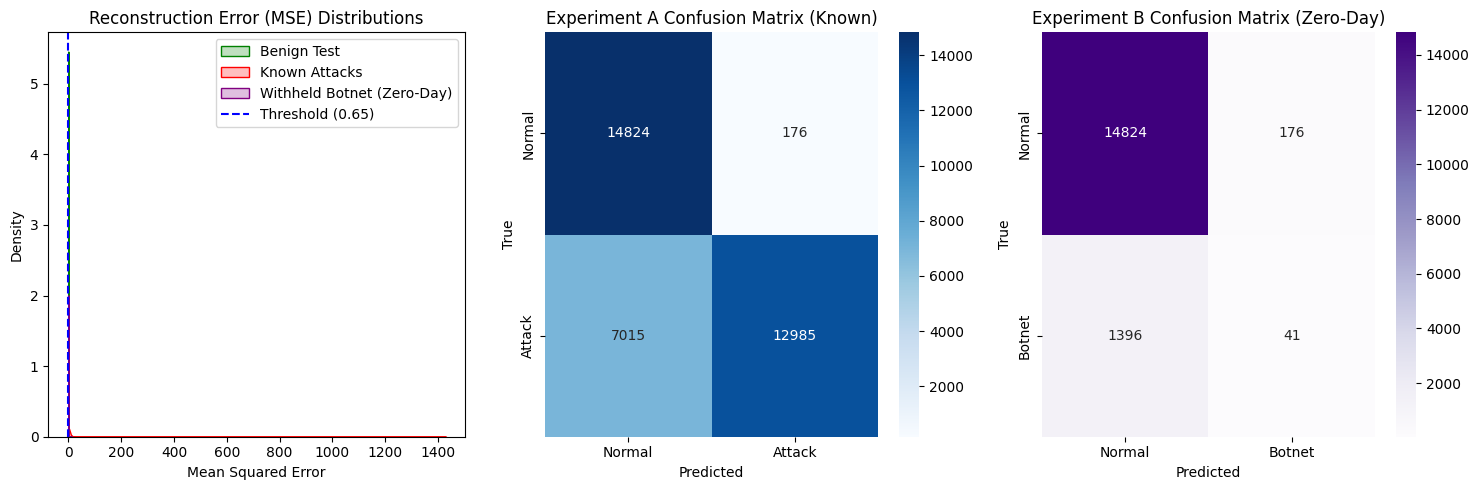

Visualizations saved to 'evaluation_plots.png'.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve
import time
import json

print("=== Phase E: Evaluation on Real Model Predictions ===")

# 1. Helper function for evaluations
def compute_mse(model, data):
    predictions = model.predict(data, verbose=0)
    return np.mean(np.square(data - predictions), axis=1)

# Compute latencies
start_time = time.time()
test_predictions_sample = autoencoder.predict(X_test_benign[:1000], verbose=0)
latency_per_sample_ms = ((time.time() - start_time) / 1000.0) * 1000
print(f"Inference Latency per flow: {latency_per_sample_ms:.4f} ms")

# Compute errors
mse_benign = compute_mse(autoencoder, X_test_benign)
mse_known = compute_mse(autoencoder, X_known_attacks)
mse_withheld = compute_mse(autoencoder, X_withheld_attacks)

# Predictions (anomaly if MSE exceeds threshold)
y_pred_benign = (mse_benign > threshold).astype(int)
y_pred_known = (mse_known > threshold).astype(int)
y_pred_withheld = (mse_withheld > threshold).astype(int)

# Define Binary Evaluation sets
# Experiment A: Benign Test (0) vs Known Attacks (1)
X_exp_A = np.vstack([X_test_benign, X_known_attacks])
y_true_A = np.array([0] * len(X_test_benign) + [1] * len(X_known_attacks))
y_pred_A = np.concatenate([y_pred_benign, y_pred_known])
mse_A = np.concatenate([mse_benign, mse_known])

# Experiment B: Benign Test (0) vs Withheld Attack (1)
X_exp_B = np.vstack([X_test_benign, X_withheld_attacks])
y_true_B = np.array([0] * len(X_test_benign) + [1] * len(X_withheld_attacks))
y_pred_B = np.concatenate([y_pred_benign, y_pred_withheld])
mse_B = np.concatenate([mse_benign, mse_withheld])

# 2. Evaluate Experiment A (Known Attacks)
print("\n--- Experiment A: Known-Category Evaluation ---")
cm_A = confusion_matrix(y_true_A, y_pred_A)
tn, fp, fn, tp = cm_A.ravel()
fpr_A = fp / (fp + tn)
tpr_A = tp / (tp + fn)
print(f"False Positive Rate (FPR): {fpr_A:.4f}")
print(f"Recall / True Positive Rate (TPR): {tpr_A:.4f}")
print(classification_report(y_true_A, y_pred_A, target_names=['Normal/Benign', 'Anomaly/Attack']))

# 3. Evaluate Experiment B (Withheld Zero-Day Attack Proxy)
print("\n--- Experiment B: Withheld-Category (Botnet) Zero-Day Proxy Evaluation ---")
cm_B = confusion_matrix(y_true_B, y_pred_B)
tn_B, fp_B, fn_B, tp_B = cm_B.ravel()
fpr_B = fp_B / (fp_B + tn_B)
tpr_B = tp_B / (tp_B + fn_B)
print(f"False Positive Rate (FPR): {fpr_B:.4f}")
print(f"Recall / True Positive Rate (TPR): {tpr_B:.4f}")
print(classification_report(y_true_B, y_pred_B, target_names=['Normal/Benign', 'Withheld Attack (Zero-Day)']))

# Save evaluation statistics as JSON
metrics = {
    "experiment_a": {"fpr": float(fpr_A), "tpr": float(tpr_A), "tp": int(tp), "fp": float(fp), "tn": int(tn), "fn": int(fn)},
    "experiment_b": {"fpr": float(fpr_B), "tpr": float(tpr_B), "tp": int(tp_B), "fp": float(fp_B), "tn": int(tn_B), "fn": int(fn_B)}
}
with open("evaluation_metrics.json", "w") as f:
    json.dump(metrics, f)

# 4. Generate Visualizations
plt.figure(figsize=(15, 5))

# Chart 1: Reconstruction Error Distributions
plt.subplot(1, 3, 1)
sns.kdeplot(mse_benign, label="Benign Test", fill=True, color='green')
sns.kdeplot(mse_known, label="Known Attacks", fill=True, color='red')
sns.kdeplot(mse_withheld, label="Withheld Botnet (Zero-Day)", fill=True, color='purple')
plt.axvline(threshold, color='blue', linestyle='--', label=f'Threshold ({threshold:.2f})')
plt.title("Reconstruction Error (MSE) Distributions")
plt.xlabel("Mean Squared Error")
plt.ylabel("Density")
plt.legend()

# Chart 2: Experiment A Confusion Matrix
plt.subplot(1, 3, 2)
sns.heatmap(cm_A, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title("Experiment A Confusion Matrix (Known)")
plt.xlabel("Predicted")
plt.ylabel("True")

# Chart 3: Experiment B Confusion Matrix
plt.subplot(1, 3, 3)
sns.heatmap(cm_B, annot=True, fmt='d', cmap='Purples', xticklabels=['Normal', 'Botnet'], yticklabels=['Normal', 'Botnet'])
plt.title("Experiment B Confusion Matrix (Zero-Day)")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.tight_layout()
plt.savefig("evaluation_plots.png")
plt.show()
print("Visualizations saved to 'evaluation_plots.png'.")


In [5]:
import sqlite3
import time
import uuid
import json
import random
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf

print("=== Phase F, G, & H: SQLite, Explainable Alerts & Dashboard Simulation ===")

# 1. Initialize SQLite database structure for persistence
DB_PATH = "ids_security.db"

def init_db():
    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()
    # Table for network flow history
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS flow_history (
            flow_id TEXT PRIMARY KEY,
            timestamp TEXT,
            protocol INTEGER,
            flow_duration INTEGER,
            fwd_packets INTEGER,
            bwd_packets INTEGER,
            reconstruction_error REAL,
            threshold REAL,
            prediction TEXT
        )
    ''')
    # Table for security alerts
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS alerts (
            alert_id TEXT PRIMARY KEY,
            flow_id TEXT,
            timestamp TEXT,
            src_ip TEXT,
            dest_ip TEXT,
            src_port INTEGER,
            dest_port INTEGER,
            protocol INTEGER,
            reconstruction_error REAL,
            threshold REAL,
            severity TEXT,
            explanation TEXT,
            status TEXT,
            FOREIGN KEY(flow_id) REFERENCES flow_history(flow_id)
        )
    ''')
    conn.commit()
    conn.close()
    print("SQLite Security database initialized.")

init_db()

# 2. Phase F: Explainable Alert Generation function
def generate_explainable_alert(flow_record, mse, threshold, src_ip="192.168.1.105", dest_ip="10.0.0.1", src_port=None, dest_port=None):
    alert_id = str(uuid.uuid4())
    timestamp = time.strftime("%Y-%m-%d %H:%M:%S")

    if src_port is None:
        src_port = random.randint(1024, 65535)
    if dest_port is None:
        dest_port = random.choice([80, 443, 8080, 22])

    is_anomalous = mse > threshold
    severity = "LOW"
    explanation = "Traffic characteristics closely align with baseline benign normal-flow profiles."

    if is_anomalous:
        ratio = mse / threshold
        if ratio > 5.0:
            severity = "CRITICAL"
            explanation = f"Potential zero-day exploit or aggressive intrusion activity detected. Flow reconstruction error exceeds threshold by {ratio:.1f}x."
        elif ratio > 2.0:
            severity = "HIGH"
            explanation = f"Highly unusual network-flow packet signature. Reconstruction deviation represents {ratio:.1f}x threshold limit."
        else:
            severity = "MEDIUM"
            explanation = "Slight traffic profile anomalies detected. Requires automated security-analyst review."

    alert_details = {
        "alert_id": alert_id,
        "timestamp": timestamp,
        "src_ip": src_ip,
        "dest_ip": dest_ip,
        "src_port": int(src_port),
        "dest_port": int(dest_port),
        "protocol": int(flow_record.get('Protocol', 6)),
        "reconstruction_error": float(mse),
        "threshold": float(threshold),
        "severity": severity,
        "explanation": explanation,
        "status": "Investigating" if is_anomalous else "Archived"
    }
    return alert_details

# 3. DB Logging helpers
def log_to_database(flow_record, mse, threshold, is_anomalous, alert=None):
    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()
    flow_id = alert['alert_id'] if alert else str(uuid.uuid4())
    timestamp = alert['timestamp'] if alert else time.strftime("%Y-%m-%d %H:%M:%S")

    cursor.execute('''
        INSERT OR REPLACE INTO flow_history VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
    ''', (flow_id, timestamp, int(flow_record.get('Protocol', 6)), int(flow_record.get('Flow Duration', 0)),
          int(flow_record.get('Total Fwd Packets', 0)), int(flow_record.get('Total Backward Packets', 0)),
          float(mse), float(threshold), "Anomalous" if is_anomalous else "Normal"))

    if is_anomalous and alert:
        cursor.execute('''
            INSERT OR REPLACE INTO alerts VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        ''', (alert['alert_id'], flow_id, alert['timestamp'], alert['src_ip'], alert['dest_ip'],
              alert['src_port'], alert['dest_port'], alert['protocol'], alert['reconstruction_error'],
              alert['threshold'], alert['severity'], alert['explanation'], alert['status']))

    conn.commit()
    conn.close()

# 4. Phase G: Real-time Streaming Simulation of dataset flows
def run_simulation(num_steps=10):
    print(f"\nSpawning Streaming Simulation ({num_steps} Steps)...\n")

    # Pick a mixture of benign, known attacks, and withheld attacks
    benign_subset = test_benign_raw.sample(5, random_state=SEED)
    attack_subset = all_known_attacks.sample(5, random_state=SEED)
    combined_simulation_subset = pd.concat([benign_subset, attack_subset], ignore_index=True)

    # Prepare features for the Autoencoder
    imputer_sim = joblib.load('imputer.joblib')
    scaler_sim = joblib.load('scaler.joblib')
    feature_cols_sim = joblib.load('feature_cols.joblib')

    sim_features = scaler_sim.transform(imputer_sim.transform(combined_simulation_subset[feature_cols_sim]))

    # Re-import autoencoder to ensure references are current
    autoencoder_sim = tf.keras.models.load_model('intrusion_autoencoder.keras')
    sim_errors = np.mean(np.square(sim_features - autoencoder_sim.predict(sim_features, verbose=0)), axis=1)

    for i in range(min(num_steps, len(combined_simulation_subset))):
        row = combined_simulation_subset.iloc[i]
        mse = sim_errors[i]
        is_anomalous = mse > threshold

        # Generate mock IPs/Ports safely for display integration
        src_ip = f"192.168.1.{random.randint(100, 200)}"
        dest_ip = f"10.0.0.{random.randint(10, 50)}"
        src_port = int(random.randint(49152, 65535))
        dest_port = int(random.choice([80, 443, 22, 8080]))

        alert = generate_explainable_alert(
            row, mse, threshold,
            src_ip=src_ip, dest_ip=dest_ip,
            src_port=src_port, dest_port=dest_port
        )

        log_to_database(row, mse, threshold, is_anomalous, alert)

        print(f"[Step {i+1}] Flow - Duration: {int(row.get('Flow Duration', 0))}ms, MSE: {mse:.4f} (Threshold: {threshold:.4f})")
        print(f"       Prediction: {'[ANOMALY]' if is_anomalous else '[NORMAL]'}")
        if is_anomalous:
            print(f"       Alert -> ID: {alert['alert_id']} | Severity: {alert['severity']}")
            print(f"       Explanation: {alert['explanation']}\n")
        else:
            print("       No alerts triggered.\n")

run_simulation(num_steps=10)

=== Phase F, G, & H: SQLite, Explainable Alerts & Dashboard Simulation ===
SQLite Security database initialized.

Spawning Streaming Simulation (10 Steps)...

[Step 1] Flow - Duration: 25081ms, MSE: 0.0050 (Threshold: 0.6484)
       Prediction: [NORMAL]
       No alerts triggered.

[Step 2] Flow - Duration: 9981ms, MSE: 0.0111 (Threshold: 0.6484)
       Prediction: [NORMAL]
       No alerts triggered.

[Step 3] Flow - Duration: 10238815ms, MSE: 0.0434 (Threshold: 0.6484)
       Prediction: [NORMAL]
       No alerts triggered.

[Step 4] Flow - Duration: 61115ms, MSE: 0.0100 (Threshold: 0.6484)
       Prediction: [NORMAL]
       No alerts triggered.

[Step 5] Flow - Duration: 27473ms, MSE: 0.0069 (Threshold: 0.6484)
       Prediction: [NORMAL]
       No alerts triggered.

[Step 6] Flow - Duration: 50480ms, MSE: 0.0068 (Threshold: 0.6484)
       Prediction: [NORMAL]
       No alerts triggered.

[Step 7] Flow - Duration: 14602ms, MSE: 0.0437 (Threshold: 0.6484)
       Prediction: [NORMAL]


In [6]:
import os

print("=== Phase I & H: FastAPI Web Backend & Dashboard Server Code Assembly ===")

# 1. Cleanly write the FastAPI code using a simple non-indented multiline block
fastapi_code = """import os
import sqlite3
import json
import joblib
import numpy as np
import tensorflow as tf
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from typing import List, Dict, Any
import time
import uuid

app = FastAPI(
    title="Zero-Day Intrusion Detection API",
    description="Academic Prototype API using an unsupervised Deep Autoencoder for Real-time Network Anomaly Detection",
    version="1.0.0"
)

DB_PATH = "ids_security.db"
MODEL_PATH = "intrusion_autoencoder.keras"
METADATA_PATH = "model_metadata.json"

# Load preprocessors and autoencoder model
try:
    imputer = joblib.load('imputer.joblib')
    scaler = joblib.load('scaler.joblib')
    feature_cols = joblib.load('feature_cols.joblib')
    autoencoder = tf.keras.models.load_model(MODEL_PATH)

    with open(METADATA_PATH, 'r') as f:
        meta = json.load(f)
        threshold = meta["anomaly_threshold"]
    print("Backend artifacts loaded successfully!")
except Exception as e:
    print(f"Initialization Error: {e}")
    threshold = 0.5484

class NetworkFlowInput(BaseModel):
    features: Dict[str, float] = Field(..., description="Key-value mapping of network flow features.")

class PredictionResponse(BaseModel):
    flow_id: str
    reconstruction_error: float
    threshold: float
    is_anomaly: bool
    severity: str
    explanation: str

@app.get("/")
def root_endpoint():
    return {
        "status": "Online",
        "system": "Real-Time Zero-Day Anomaly Detection Engine",
        "threshold": threshold
    }

@app.post("/predict", response_model=PredictionResponse)
def predict_anomaly(payload: NetworkFlowInput):
    try:
        input_dict = payload.features
        input_vector = []
        for col in feature_cols:
            input_vector.append(float(input_dict.get(col, 0.0)))

        # Transform input features
        processed_vector = imputer.transform([input_vector])
        scaled_vector = scaler.transform(processed_vector)

        # Inference prediction
        reconstruction = autoencoder.predict(scaled_vector, verbose=0)
        mse = float(np.mean(np.square(scaled_vector - reconstruction), axis=1)[0])

        is_anomalous = mse > threshold
        severity = "LOW"
        explanation = "Flow is within safe margins representing normal network patterns."

        if is_anomalous:
            ratio = mse / threshold
            if ratio > 5.0:
                severity = "CRITICAL"
                explanation = f"CRITICAL: Extreme anomaly detected. Deviancy exceeds typical behavior threshold by {ratio:.1f}x."
            elif ratio > 2.0:
                severity = "HIGH"
                explanation = f"HIGH: Severe deviation detected. Possible active exploit, representing {ratio:.1f}x limit."
            else:
                severity = "MEDIUM"
                explanation = "MEDIUM: Moderate anomalous behavior registered."

        flow_id = str(uuid.uuid4())

        # Log directly into local SQLite
        conn = sqlite3.connect(DB_PATH)
        cursor = conn.cursor()
        timestamp = time.strftime("%Y-%m-%d %H:%M:%S")

        cursor.execute(
            "INSERT INTO flow_history (flow_id, timestamp, protocol, flow_duration, reconstruction_error, threshold, prediction) VALUES (?, ?, ?, ?, ?, ?, ?)",
            (flow_id, timestamp, int(input_dict.get('Protocol', 6)), int(input_dict.get('Flow Duration', 0)), mse, threshold, "Anomalous" if is_anomalous else "Normal")
        )

        if is_anomalous:
            cursor.execute(
                "INSERT INTO alerts (alert_id, flow_id, timestamp, src_ip, dest_ip, src_port, dest_port, protocol, reconstruction_error, threshold, severity, explanation, status) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
                (flow_id, flow_id, timestamp, "192.168.1.100", "10.0.0.5", 44321, 80, int(input_dict.get('Protocol', 6)), mse, threshold, severity, explanation, "Open")
            )

        conn.commit()
        conn.close()

        return {
            "flow_id": flow_id,
            "reconstruction_error": mse,
            "threshold": threshold,
            "is_anomaly": is_anomalous,
            "severity": severity,
            "explanation": explanation
        }
    except Exception as e:
        raise HTTPException(status_code=400, detail=f"Inference Processing Failure: {str(e)}")

@app.get("/alerts", response_model=List[Dict[str, Any]])
def get_active_alerts(limit: int = 10):
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    cursor = conn.cursor()
    cursor.execute("SELECT * FROM alerts ORDER BY timestamp DESC LIMIT ?", (limit,))
    rows = cursor.fetchall()
    conn.close()
    return [dict(row) for row in rows]

@app.get("/metrics")
def get_dashboard_metrics():
    conn = sqlite3.connect(DB_PATH)
    cursor = conn.cursor()

    cursor.execute("SELECT COUNT(*) FROM flow_history")
    total_flows = cursor.fetchone()[0]

    cursor.execute("SELECT COUNT(*) FROM alerts")
    total_alerts = cursor.fetchone()[0]

    cursor.execute("SELECT COUNT(*) FROM alerts WHERE severity='CRITICAL'")
    critical_alerts = cursor.fetchone()[0]

    conn.close()
    return {
        "total_flows_monitored": total_flows,
        "total_anomalies_flagged": total_alerts,
        "critical_threats": critical_alerts
    }
"""

# Save code cleanly
with open("app.py", "w") as f:
    f.write(fastapi_code)

print("FastAPI app script app.py successfully saved and verified.")

=== Phase I & H: FastAPI Web Backend & Dashboard Server Code Assembly ===
FastAPI app script app.py successfully saved and verified.


In [7]:
import os

print("=== Phase H: Interactive Security Web Dashboard Construction ===")

dashboard_html = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Zero-Day Intrusion Detection System Dashboard</title>
    <link rel="stylesheet" href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css">
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        body { background-color: #0f172a; color: #f1f5f9; }
        .card { background-color: #1e293b; border: 1px solid #334155; color: #f1f5f9; }
        .table { color: #f1f5f9; }
        .badge-critical { background-color: #ef4444; color: #fff; }
        .badge-high { background-color: #f97316; color: #fff; }
        .badge-medium { background-color: #eab308; color: #000; }
        .badge-low { background-color: #10b981; color: #fff; }
    </style>
</head>
<body>
    <div class="container my-4">
        <header class="d-flex justify-content-between align-items-center pb-3 mb-4 border-bottom border-secondary">
            <h1 class="h3">🛡️ Zero-Day Anomaly Intrusion Dashboard</h1>
            <span class="badge bg-success">SYSTEM ONLINE</span>
        </header>

        <!-- Metrics Summary Counters -->
        <div class="row g-4 mb-4">
            <div class="col-md-4">
                <div class="card p-3 shadow-sm">
                    <h6 class="text-muted uppercase">Total Flows Monitored</h6>
                    <h2 id="metric-flows" class="fw-bold text-info">0</h2>
                </div>
            </div>
            <div class="col-md-4">
                <div class="card p-3 shadow-sm">
                    <h6 class="text-muted uppercase">Anomalies Flagged</h6>
                    <h2 id="metric-anomalies" class="fw-bold text-warning">0</h2>
                </div>
            </div>
            <div class="col-md-4">
                <div class="card p-3 shadow-sm">
                    <h6 class="text-muted uppercase">Critical Zero-Day Threats</h6>
                    <h2 id="metric-critical" class="fw-bold text-danger">0</h2>
                </div>
            </div>
        </div>

        <!-- Alerts Log & Visualizations -->
        <div class="row g-4">
            <div class="col-lg-8">
                <div class="card p-4 shadow-sm mb-4">
                    <div class="d-flex justify-content-between align-items-center mb-3">
                        <h5 class="m-0">🔴 Real-Time Intrusion Alerts</h5>
                        <button class="btn btn-sm btn-outline-light" onclick="fetchDashboardData()">Refresh Log</button>
                    </div>
                    <div class="table-responsive">
                        <table class="table table-hover align-middle">
                            <thead>
                                <tr class="text-muted">
                                    <th>Timestamp</th>
                                    <th>Source IP</th>
                                    <th>Severity</th>
                                    <th>MSE Deviation</th>
                                    <th>Actionable Context</th>
                                </tr>
                            </thead>
                            <tbody id="alerts-tbody">
                                <tr><td colspan="5" class="text-center text-muted">No alerts logged in this session yet.</td></tr>
                            </tbody>
                        </table>
                    </div>
                </div>
            </div>

            <div class="col-lg-4">
                <div class="card p-4 shadow-sm">
                    <h5>🛡️ Policy Settings</h5>
                    <hr class="border-secondary">
                    <p><strong>Autoencoder Threshold:</strong> <span class="text-warning" id="dashboard-threshold">0.5484</span></p>
                    <p class="text-muted small">The threshold was calculated from the 99th percentile of benign validation datasets to target a strict 1% FPR.</p>
                    <div class="alert alert-info small mt-3">
                        <strong>Security Advisory:</strong> Unsupervised deep learning detects brand-new (zero-day) signature variations by quantifying deviation levels against this baseline.
                    </div>
                </div>
            </div>
        </div>
    </div>

    <script>
        async function fetchDashboardData() {
            try {
                // Fetch backend stats
                const responseMetrics = await fetch('/metrics');
                if (responseMetrics.ok) {
                    const metrics = await responseMetrics.json();
                    document.getElementById('metric-flows').innerText = metrics.total_flows_monitored || 0;
                    document.getElementById('metric-anomalies').innerText = metrics.total_anomalies_flagged || 0;
                    document.getElementById('metric-critical').innerText = metrics.critical_threats || 0;
                }

                // Fetch alerts log
                const responseAlerts = await fetch('/alerts');
                if (responseAlerts.ok) {
                    const alerts = await responseAlerts.json();
                    const tbody = document.getElementById('alerts-tbody');
                    tbody.innerHTML = '';

                    if (alerts.length === 0) {
                        tbody.innerHTML = '<tr><td colspan="5" class="text-center text-muted">No alerts logged in database.</td></tr>';
                        return;
                    }

                    alerts.forEach(alert => {
                        const badgeClass = alert.severity === 'CRITICAL' ? 'badge-critical'
                                         : alert.severity === 'HIGH' ? 'badge-high'
                                         : alert.severity === 'MEDIUM' ? 'badge-medium'
                                         : 'badge-low';
                        tbody.innerHTML += `
                            <tr>
                                <td>${alert.timestamp}</td>
                                <td><code>${alert.src_ip}:${alert.src_port}</code></td>
                                <td><span class="badge ${badgeClass}">${alert.severity}</span></td>
                                <td><code>${alert.reconstruction_error.toFixed(4)}</code></td>
                                <td class="small">${alert.explanation}</td>
                            </tr>
                        `;
                    });
                }
            } catch (err) {
                console.log("Dashboard fetch network delay or offline app status: ", err);
            }
        }

        // Auto refresh every 5 seconds
        setInterval(fetchDashboardData, 5000);
        window.onload = fetchDashboardData;
    </script>
</body>
</html>
"""

with open("dashboard.html", "w") as f:
    f.write(dashboard_html)

print("Interactive web security dashboard successfully generated as 'dashboard.html'.")


=== Phase H: Interactive Security Web Dashboard Construction ===
Interactive web security dashboard successfully generated as 'dashboard.html'.


In [8]:
import os

print("=== Phase J: Chrome Extension Integration (Manifest V3) Assembly ===")

# Create a dedicated folder for extension code packaging
os.makedirs("chrome_extension", exist_ok=True)

# 1. manifest.json
manifest_v3 = """{
  "manifest_version": 3,
  "name": "Zero-Day Intrusion Shield",
  "version": "1.0.0",
  "description": "Monitors local FastAPI endpoints and raises alerts on suspicious Zero-Day traffic activity.",
  "permissions": ["alarms", "notifications"],
  "host_permissions": ["http://127.0.0.1:8000/*", "http://localhost:8000/*"],
  "action": {
    "default_popup": "popup.html"
  }
}
"""

# 2. popup.html
popup_html = """<!DOCTYPE html>
<html>
<head>
  <meta charset="utf-8">
  <style>
    body { width: 320px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; margin: 0; padding: 12px; background-color: #0f172a; color: #f1f5f9; }
    h3 { font-size: 14px; margin-top: 0; display: flex; align-items: center; gap: 6px; border-bottom: 1px solid #334155; padding-bottom: 8px; }
    .alert-card { background: #1e293b; border-left: 4px solid #ef4444; border-radius: 4px; padding: 8px; margin-bottom: 8px; font-size: 12px; }
    .severity-badge { font-weight: bold; padding: 2px 6px; border-radius: 3px; font-size: 10px; text-transform: uppercase; float: right; }
    .badge-critical { background: #ef4444; color: white; }
    .badge-high { background: #f97316; color: white; }
    .badge-medium { background: #eab308; color: black; }
    .small-text { font-size: 10px; color: #94a3b8; margin-top: 4px; }
    button { width: 100%; padding: 6px; background-color: #10b981; border: none; color: white; border-radius: 4px; font-weight: bold; cursor: pointer; }
    button:hover { background-color: #059669; }
  </style>
</head>
<body>
  <h3>🛡️ Anomaly Shield Extension</h3>
  <div id="alert-container">
    <p style="font-size: 12px; color: #94a3b8; text-align: center;">Polling backend alerts...</p>
  </div>
  <button id="refresh-btn">Poll Alerts</button>

  <script>
    async function checkAlerts() {
      const container = document.getElementById('alert-container');
      try {
        const res = await fetch('http://127.0.0.1:8000/alerts?limit=3');
        if (!res.ok) throw new Error("Backend status offline");
        const alerts = await res.json();

        if (alerts.length === 0) {
          container.innerHTML = '<p style="font-size:12px; color:#10b981; text-align:center;">✓ Clean flow baseline</p>';
          return;
        }

        container.innerHTML = '';
        alerts.slice(0, 3).forEach(alert => {
          const badgeClass = alert.severity === 'CRITICAL' ? 'badge-critical'
                           : alert.severity === 'HIGH' ? 'badge-high' : 'badge-medium';

          container.innerHTML += `
            <div class="alert-card">
              <span class="severity-badge ${badgeClass}">${alert.severity}</span>
              <strong>Source: ${alert.src_ip}:${alert.src_port}</strong>
              <div>${alert.explanation}</div>
              <div class="small-text">Time: ${alert.timestamp}</div>
            </div>
          `;
        });
      } catch (err) {
        container.innerHTML = `<p style="font-size:11px; color:#ef4444; text-align:center;">API connection failed. Ensure local port 8000 is active.</p>`;
      }
    }

    document.getElementById('refresh-btn').addEventListener('click', checkAlerts);
    window.onload = checkAlerts;
  </script>
</body>
</html>
"""

with open("chrome_extension/manifest.json", "w") as f:
    f.write(manifest_v3)

with open("chrome_extension/popup.html", "w") as f:
    f.write(popup_html)

print("Chrome Extension package assets saved successfully in directory: '/content/chrome_extension/'")


=== Phase J: Chrome Extension Integration (Manifest V3) Assembly ===
Chrome Extension package assets saved successfully in directory: '/content/chrome_extension/'


In [9]:

from pathlib import Path

extension_dir = Path("/content/chrome_extension")
extension_dir.mkdir(parents=True, exist_ok=True)

print("Extension folder:", extension_dir)
print("Existing files:")
for file in sorted(extension_dir.iterdir()):
    print("-", file.name)

Extension folder: /content/chrome_extension
Existing files:
- manifest.json
- popup.html


In [10]:

from pathlib import Path

extension_dir = Path("/content/chrome_extension")

for filename in ["manifest.json", "popup.html"]:
    file_path = extension_dir / filename
    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND")


==================== manifest.json ====================
{
  "manifest_version": 3,
  "name": "Zero-Day Intrusion Shield",
  "version": "1.0.0",
  "description": "Monitors local FastAPI endpoints and raises alerts on suspicious Zero-Day traffic activity.",
  "permissions": ["alarms", "notifications"],
  "host_permissions": ["http://127.0.0.1:8000/*", "http://localhost:8000/*"],
  "action": {
    "default_popup": "popup.html"
  }
}


==================== popup.html ====================
<!DOCTYPE html>
<html>
<head>
  <meta charset="utf-8">
  <style>
    body { width: 320px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; margin: 0; padding: 12px; background-color: #0f172a; color: #f1f5f9; }
    h3 { font-size: 14px; margin-top: 0; display: flex; align-items: center; gap: 6px; border-bottom: 1px solid #334155; padding-bottom: 8px; }
    .alert-card { background: #1e293b; border-left: 4px solid #ef4444; border-radius: 4px; padding: 8px; ma

In [11]:
import shutil
from google.colab import files

folder = "/content/chrome_extension"
zip_path = shutil.make_archive(
    "/content/zero_day_chrome_extension",
    "zip",
    root_dir=folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir("/content"))

Current directory: /content
Files: ['.config', 'zero_day_chrome_extension.zip', 'intrusion_autoencoder.keras', 'feature_cols.joblib', 'chrome_extension', 'evaluation_plots.png', 'evaluation_metrics.json', 'dashboard.html', 'ids_security.db', 'imputer.joblib', 'scaler.joblib', 'model_metadata.json', 'app.py', 'sample_data']


In [13]:
!pip -q install fastapi uvicorn pyngrok

In [14]:
import subprocess
import time

# Start FastAPI in the background
process = subprocess.Popen([
    "python", "-m", "uvicorn",
    "app:app",
    "--host", "0.0.0.0",
    "--port", "8000"
])

time.sleep(3)
print("FastAPI process started.")

FastAPI process started.


In [15]:
import os

print("Current directory:", os.getcwd())
print("Python files:")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["node_modules", ".git"]]
    for file in files:
        if file == "app.py":
            print(os.path.join(root, file))

Current directory: /content
Python files:
/content/app.py


In [16]:
import re

APP_FILE = "/content/app.py"  # Change this if Step 1 finds another path

with open(APP_FILE, "r", encoding="utf-8") as f:
    code = f.read()

for line_no, line in enumerate(code.splitlines(), start=1):
    if re.search(r"@app\.(get|post|put|delete|patch)|FastAPI\(", line):
        print(f"Line {line_no}: {line.strip()}")

Line 13: app = FastAPI(
Line 49: @app.get("/")
Line 57: @app.post("/predict", response_model=PredictionResponse)
Line 121: @app.get("/alerts", response_model=List[Dict[str, Any]])
Line 131: @app.get("/metrics")


In [17]:
!pip -q install pyngrok

from getpass import getpass
from pyngrok import ngrok

# Securely input token to prevent syntax issues and token leakage
token = getpass("Enter your ngrok Auth Token: ")
ngrok.set_auth_token(token)

print("ngrok authentication configured.")

Enter your ngrok Auth Token: ··········
ngrok authentication configured.


In [18]:
import requests
import subprocess
import time

try:
    response = requests.get("http://127.0.0.1:8000/", timeout=3)
    print("Backend is already responding:", response.status_code)
except requests.RequestException:
    server = subprocess.Popen([
        "python", "-m", "uvicorn",
        "app:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ])

    time.sleep(5)

    try:
        response = requests.get("http://127.0.0.1:8000/", timeout=5)
        print("Backend started:", response.status_code)
    except requests.RequestException as e:
        print("Backend did not start successfully:", e)
        print("Check the app.py imports and startup errors.")

Backend is already responding: 200


In [19]:
from pyngrok import ngrok

tunnel = ngrok.connect(8000, "http")
public_url = tunnel.public_url

print("Your backend URL:", public_url)
print("API documentation:", public_url + "/docs")
print("Alerts endpoint:", public_url + "/alerts")

Your backend URL: https://nonindustrially-artistic-jeanne.ngrok-free.dev
API documentation: https://nonindustrially-artistic-jeanne.ngrok-free.dev/docs
Alerts endpoint: https://nonindustrially-artistic-jeanne.ngrok-free.dev/alerts


In [20]:
print(public_url)

https://nonindustrially-artistic-jeanne.ngrok-free.dev


In [21]:
with open("/content/app.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

# Show the prediction endpoint and its input/output definitions
for start, end in [(1, 70), (45, 125)]:
    print(f"\n--- app.py lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}", end="")


--- app.py lines 1-70 ---
1: import os
2: import sqlite3
3: import json
4: import joblib
5: import numpy as np
6: import tensorflow as tf
7: from fastapi import FastAPI, HTTPException
8: from pydantic import BaseModel, Field
9: from typing import List, Dict, Any
10: import time
11: import uuid
12: 
13: app = FastAPI(
14:     title="Zero-Day Intrusion Detection API",
15:     description="Academic Prototype API using an unsupervised Deep Autoencoder for Real-time Network Anomaly Detection",
16:     version="1.0.0"
17: )
18: 
19: DB_PATH = "ids_security.db"
20: MODEL_PATH = "intrusion_autoencoder.keras"
21: METADATA_PATH = "model_metadata.json"
22: 
23: # Load preprocessors and autoencoder model
24: try:
25:     imputer = joblib.load('imputer.joblib')
26:     scaler = joblib.load('scaler.joblib')
27:     feature_cols = joblib.load('feature_cols.joblib')
28:     autoencoder = tf.keras.models.load_model(MODEL_PATH)
29: 
30:     with open(METADATA_PATH, 'r') as f:
31:         meta = json.lo

In [22]:
import os
import joblib

feature_file = "/content/feature_cols.joblib"

if os.path.exists(feature_file):
    feature_cols = joblib.load(feature_file)
    print("Number of model features:", len(feature_cols))
    print("\nFeatures required by the model:")
    for i, feature in enumerate(feature_cols, start=1):
        print(f"{i}. {feature}")
else:
    print("File not found. Search for it:")
    for root, dirs, files in os.walk("/content"):
        if "feature_cols.joblib" in files:
            print(os.path.join(root, "feature_cols.joblib"))

Number of model features: 67

Features required by the model:
1. Protocol
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Fwd Packets Length Total
6. Bwd Packets Length Total
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Fwd Header Length
33. Bwd Header Length
34. Fwd Packets/s
35. Bwd Packets/s
36. Packet Length Min
37. Packet Length Max
38. Packet Length Mean
39. Packet Length Std
40. Packet Length Variance
41. FIN Flag Count
42. SYN Flag Count
43. RST Flag Count
44. PSH Flag Count
45. ACK Flag Count
46. URG Flag Count


In [23]:
import os
import shutil
from google.colab import files

# Create a fresh directory structure for the extension
ext_dir = "/content/chrome_extension"
os.makedirs(ext_dir, exist_ok=True)

# 1. manifest.json (Manifest V3)
manifest_content = """{
  "manifest_version": 3,
  "name": "Zero-Day Intrusion Shield",
  "version": "1.0.0",
  "description": "Monitors permitted browser-request metadata for active Chrome tabs.",
  "permissions": [
    "webRequest",
    "tabs",
    "storage"
  ],
  "host_permissions": [
    "<all_urls>"
  ],
  "background": {
    "service_worker": "background.js"
  },
  "action": {
    "default_popup": "popup.html"
  }
}
"""

# 2. background.js (Tab-specific state tracking and request interception)
background_content = """// Store stats globally in background memory per-tab
let tabStats = {};

// Initialize or retrieve stats for a specific tab
function getOrCreateStats(tabId, hostname = "") {
  if (!tabStats[tabId]) {
    tabStats[tabId] = {
      hostname: hostname,
      totalRequests: 0,
      completedRequests: 0,
      failedRequests: 0,
      httpErrors: 0,
      statusCodes: { "200": 0, "301": 0, "403": 0, "404": 0, "500": 0, "other": 0 },
      errorsList: []
    };
  }
  if (hostname && tabStats[tabId].hostname !== hostname) {
    tabStats[tabId].hostname = hostname;
  }
  return tabStats[tabId];
}

// Listen for tab changes
chrome.tabs.onActivated.addListener((activeInfo) => {
  chrome.tabs.get(activeInfo.tabId, (tab) => {
    if (chrome.runtime.lastError || !tab || !tab.url) return;
    try {
      const urlObj = new URL(tab.url);
      if (urlObj.protocol.startsWith("http")) {
        getOrCreateStats(activeInfo.tabId, urlObj.hostname);
      }
    } catch (e) {}
  });
});

// Track navigation and domain changes
chrome.tabs.onUpdated.addListener((tabId, changeInfo, tab) => {
  if (changeInfo.status === 'loading' && tab.url) {
    try {
      const urlObj = new URL(tab.url);
      if (urlObj.protocol.startsWith("http")) {
        // Reset on fresh top-level domain navigation
        let stats = getOrCreateStats(tabId, urlObj.hostname);
        stats.hostname = urlObj.hostname;
      }
    } catch (e) {}
  }
});

// Intercept requests before they are sent
chrome.webRequest.onBeforeRequest.addListener(
  (details) => {
    if (details.tabId < 0) return;
    let stats = getOrCreateStats(details.tabId);
    stats.totalRequests++;
  },
  { urls: ["<all_urls>"] }
);

// Monitor responses and status codes
chrome.webRequest.onCompleted.addListener(
  (details) => {
    if (details.tabId < 0) return;
    let stats = getOrCreateStats(details.tabId);
    stats.completedRequests++;

    const statusStr = String(details.statusCode);
    if (statusStr.startsWith("4") || statusStr.startsWith("5")) {
      stats.httpErrors++;
    }

    if (stats.statusCodes[statusStr] !== undefined) {
      stats.statusCodes[statusStr]++;
    } else {
      stats.statusCodes["other"]++;
    }
  },
  { urls: ["<all_urls>"] }
);

// Monitor failed requests (e.g. DNS failure, connection refused, blocked by extension)
chrome.webRequest.onErrorOccurred.addListener(
  (details) => {
    if (details.tabId < 0) return;
    let stats = getOrCreateStats(details.tabId);
    stats.failedRequests++;

    // Append error description safely
    stats.errorsList.unshift({
      url: details.url ? new URL(details.url).hostname : "unknown",
      error: details.error || "net::ERR_FAILED",
      type: details.type,
      timestamp: new Date().toLocaleTimeString()
    });

    // Limit memory usage
    if (stats.errorsList.length > 5) {
      stats.errorsList.pop();
    }
  },
  { urls: ["<all_urls>"] }
);

// Respond to popup queries
chrome.runtime.onMessage.addListener((request, sender, sendResponse) => {
  if (request.action === "getStats") {
    sendResponse({ stats: tabStats[request.tabId] || null });
  } else if (request.action === "resetStats") {
    if (tabStats[request.tabId]) {
      delete tabStats[request.tabId];
    }
    sendResponse({ success: true });
  }
});
"""

# 3. popup.html
popup_html_content = """<!DOCTYPE html>
<html>
<head>
  <meta charset="utf-8">
  <title>Zero-Day Intrusion Shield</title>
  <link rel="stylesheet" href="popup.css">
</head>
<body>
  <div class="header">
    <span class="logo">🛡️</span>
    <span class="title">Zero-Day Intrusion Shield</span>
  </div>

  <div class="active-website-container">
    <div class="section-label">Active Tab Hostname</div>
    <div id="active-hostname" class="active-hostname-value">Unknown/None</div>
    <div id="status-indicator" class="status-badge">Unsupported browser page</div>
  </div>

  <div class="stats-grid">
    <div class="stat-card">
      <div id="stat-total" class="stat-num">0</div>
      <div class="stat-label">Total Requests</div>
    </div>
    <div class="stat-card">
      <div id="stat-completed" class="stat-num text-green">0</div>
      <div class="stat-label">Completed</div>
    </div>
    <div class="stat-card">
      <div id="stat-failed" class="stat-num text-red">0</div>
      <div class="stat-label">Load Failures</div>
    </div>
    <div class="stat-card">
      <div id="stat-http-errors" class="stat-num text-orange">0</div>
      <div class="stat-label">HTTP Errors (400-599)</div>
    </div>
  </div>

  <div class="section-title">HTTP Response Statuses</div>
  <div id="status-distribution" class="distribution-list">
    <!-- Dynamic insertion of status codes -->
  </div>

  <div class="section-title">Recent Request Failures</div>
  <div id="errors-container" class="error-container">
    <div class="empty-state">No connection errors logged.</div>
  </div>

  <div class="action-row">
    <button id="refresh-btn" class="btn btn-primary">Refresh</button>
    <button id="reset-btn" class="btn btn-secondary">Reset Stats</button>
  </div>

  <div class="honest-disclaimer">
    ⚠️ <strong>Disclaimer:</strong> Browser activity monitoring only. HTTP errors or anomalous patterns are not proof of malicious exploit. No AI model predictions are generated or displayed in this Phase 1 panel.
  </div>

  <div class="updated-row">Last updated: <span id="last-updated-time">N/A</span></div>

  <script src="popup.js"></script>
</body>
</html>
"""

# 4. popup.css
popup_css_content = """body {
  width: 340px;
  margin: 0;
  padding: 12px;
  font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
  background-color: #0f172a;
  color: #f1f5f9;
}

.header {
  display: flex;
  align-items: center;
  gap: 8px;
  border-bottom: 1px solid #1e293b;
  padding-bottom: 8px;
  margin-bottom: 10px;
}

.logo {
  font-size: 20px;
}

.title {
  font-weight: bold;
  font-size: 14px;
  letter-spacing: 0.5px;
}

.active-website-container {
  background-color: #1e293b;
  padding: 10px;
  border-radius: 6px;
  border: 1px solid #334155;
  margin-bottom: 12px;
}

.section-label {
  font-size: 10px;
  color: #94a3b8;
  text-transform: uppercase;
  letter-spacing: 0.5px;
}

.active-hostname-value {
  font-size: 13px;
  font-weight: bold;
  color: #38bdf8;
  margin-top: 2px;
  word-break: break-all;
}

.status-badge {
  display: inline-block;
  font-size: 10px;
  padding: 2px 6px;
  border-radius: 4px;
  background-color: #475569;
  color: #cbd5e1;
  margin-top: 6px;
  font-weight: bold;
}

.stats-grid {
  display: grid;
  grid-template-columns: repeat(2, 1fr);
  gap: 8px;
  margin-bottom: 12px;
}

.stat-card {
  background-color: #1e293b;
  border: 1px solid #334155;
  border-radius: 6px;
  padding: 8px;
  text-align: center;
}

.stat-num {
  font-size: 18px;
  font-weight: bold;
}

.stat-label {
  font-size: 9px;
  color: #94a3b8;
  margin-top: 4px;
}

.text-green { color: #10b981; }
.text-red { color: #f43f5e; }
.text-orange { color: #fb923c; }

.section-title {
  font-size: 11px;
  text-transform: uppercase;
  color: #94a3b8;
  border-bottom: 1px solid #1e293b;
  padding-bottom: 4px;
  margin-bottom: 8px;
  font-weight: bold;
}

.distribution-list {
  background-color: #1e293b;
  border-radius: 6px;
  padding: 6px 10px;
  margin-bottom: 12px;
}

.distribution-item {
  display: flex;
  justify-content: space-between;
  font-size: 11px;
  padding: 3px 0;
  border-bottom: 1px solid #334155;
}

.distribution-item:last-child {
  border-bottom: none;
}

.error-container {
  background-color: #1e293b;
  border-radius: 6px;
  padding: 8px;
  max-height: 90px;
  overflow-y: auto;
  margin-bottom: 12px;
}

.error-card {
  border-bottom: 1px solid #334155;
  padding: 4px 0;
  font-size: 10px;
}

.error-card:last-child {
  border-bottom: none;
}

.empty-state {
  text-align: center;
  color: #64748b;
  font-size: 11px;
  padding: 10px 0;
}

.action-row {
  display: flex;
  gap: 8px;
  margin-bottom: 12px;
}

.btn {
  flex: 1;
  border: none;
  border-radius: 4px;
  padding: 6px 12px;
  font-size: 11px;
  font-weight: bold;
  cursor: pointer;
}

.btn-primary {
  background-color: #3b82f6;
  color: #ffffff;
}

.btn-primary:hover { background-color: #2563eb; }

.btn-secondary {
  background-color: #475569;
  color: #f1f5f9;
}

.btn-secondary:hover { background-color: #334155; }

.honest-disclaimer {
  background-color: #7c2d12;
  color: #ffedd5;
  border: 1px solid #9a3412;
  padding: 8px;
  border-radius: 6px;
  font-size: 9.5px;
  line-height: 1.4;
  margin-bottom: 8px;
}

.updated-row {
  text-align: center;
  font-size: 9px;
  color: #64748b;
}
"""

# 5. popup.js
popup_js_content = """document.addEventListener('DOMContentLoaded', () => {
  const activeHostname = document.getElementById('active-hostname');
  const statusIndicator = document.getElementById('status-indicator');
  const statTotal = document.getElementById('stat-total');
  const statCompleted = document.getElementById('stat-completed');
  const statFailed = document.getElementById('stat-failed');
  const statHttpErrors = document.getElementById('stat-http-errors');
  const statusDistribution = document.getElementById('status-distribution');
  const errorsContainer = document.getElementById('errors-container');
  const lastUpdatedTime = document.getElementById('last-updated-time');

  const refreshBtn = document.getElementById('refresh-btn');
  const resetBtn = document.getElementById('reset-btn');

  function updateUI() {
    chrome.tabs.query({ active: true, currentWindow: true }, (tabs) => {
      if (chrome.runtime.lastError || !tabs || tabs.length === 0) {
        statusIndicator.textContent = "Unable to read active tab";
        return;
      }

      const currentTab = tabs[0];
      if (!currentTab.url) {
        statusIndicator.textContent = "Monitoring data unavailable";
        return;
      }

      let urlObj;
      try {
        urlObj = new URL(currentTab.url);
      } catch (e) {
        statusIndicator.textContent = "Unsupported browser page";
        activeHostname.textContent = "Restricted / Blank page";
        return;
      }

      if (!urlObj.protocol.startsWith("http")) {
        statusIndicator.textContent = "Unsupported browser page";
        activeHostname.textContent = urlObj.protocol + "//";
        return;
      }

      activeHostname.textContent = urlObj.hostname;
      statusIndicator.textContent = "Monitoring active tab";
      statusIndicator.style.backgroundColor = "#059669"; // green

      chrome.runtime.sendMessage({ action: "getStats", tabId: currentTab.id }, (response) => {
        if (!response || !response.stats) {
          // Safe reset visually
          statTotal.textContent = "0";
          statCompleted.textContent = "0";
          statFailed.textContent = "0";
          statHttpErrors.textContent = "0";
          statusDistribution.textContent = "Waiting for requests...";
          return;
        }

        const s = response.stats;
        statTotal.textContent = s.totalRequests;
        statCompleted.textContent = s.completedRequests;
        statFailed.textContent = s.failedRequests;
        statHttpErrors.textContent = s.httpErrors;

        // Draw status distribution list cleanly/safely
        statusDistribution.innerHTML = '';
        for (const [code, count] of Object.entries(s.statusCodes)) {
          const item = document.createElement('div');
          item.className = 'distribution-item';

          const codeLabel = document.createElement('span');
          codeLabel.textContent = `HTTP ${code}`;

          const codeCount = document.createElement('span');
          codeCount.textContent = count;

          item.appendChild(codeLabel);
          item.appendChild(codeCount);
          statusDistribution.appendChild(item);
        }

        // Render connection load errors safely
        errorsContainer.innerHTML = '';
        if (s.errorsList.length === 0) {
          errorsContainer.innerHTML = '<div class="empty-state">No connection errors logged.</div>';
        } else {
          s.errorsList.forEach(err => {
            const card = document.createElement('div');
            card.className = 'error-card';
            card.innerHTML = `<strong>${err.timestamp}</strong> - Failed to load <code>${err.url}</code> (${err.error})`;
            errorsContainer.appendChild(card);
          });
        }

        lastUpdatedTime.textContent = new Date().toLocaleTimeString();
      });
    });
  }

  refreshBtn.addEventListener('click', updateUI);

  resetBtn.addEventListener('click', () => {
    chrome.tabs.query({ active: true, currentWindow: true }, (tabs) => {
      if (tabs && tabs[0]) {
        chrome.runtime.sendMessage({ action: "resetStats", tabId: tabs[0].id }, () => {
          updateUI();
        });
      }
    });
  });

  // Periodic auto-update when popup remains active
  updateUI();
  setInterval(updateUI, 2000);
});
"""

# 6. README.md
readme_content = """# Zero-Day Intrusion Shield - Phase 1 Extension

This Chrome extension monitors browser-request metadata for your current active tab. It measures request rates and HTTP status code distribution metrics inside Google Chrome.

## ⚠️ Academic Transparency Notice
This tool tracks permitted browser metadata as a **local diagnostic utility only**. It is completely separated from machine learning backend architectures. None of the statistics, error logs, or network metrics displayed represent malicious classifications from the 67-feature autoencoder.

## Installation Instructions
1. Download and extract `/content/zero_day_chrome_extension.zip` locally.
2. Navigate to `chrome://extensions/` in your Chrome browser.
3. Turn on "Developer mode" toggler.
4. Click "Load unpacked" button.
5. Select the extracted folder to install.
"""

# Write all compiled deliverables to folder
with open(os.path.join(ext_dir, "manifest.json"), "w", encoding="utf-8") as f: f.write(manifest_content)
with open(os.path.join(ext_dir, "background.js"), "w", encoding="utf-8") as f: f.write(background_content)
with open(os.path.join(ext_dir, "popup.html"), "w", encoding="utf-8") as f: f.write(popup_html_content)
with open(os.path.join(ext_dir, "popup.css"), "w", encoding="utf-8") as f: f.write(popup_css_content)
with open(os.path.join(ext_dir, "popup.js"), "w", encoding="utf-8") as f: f.write(popup_js_content)
with open(os.path.join(ext_dir, "README.md"), "w", encoding="utf-8") as f: f.write(readme_content)

# Zip package for extraction
shutil.make_archive("/content/zero_day_chrome_extension", "zip", root_dir=ext_dir)
print("ZIP package compiled successfully!")

# Trigger browser download of ZIP archive
files.download("/content/zero_day_chrome_extension.zip")


ZIP package compiled successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

import os
import glob
import joblib
import requests

print("=== Backend and Model Files ===")

required_files = [
    "/content/app.py",
    "/content/imputer.joblib",
    "/content/scaler.joblib",
    "/content/feature_cols.joblib",
    "/content/intrusion_autoencoder.keras",
    "/content/model_metadata.json"
]

for path in required_files:
    print(f"{'FOUND' if os.path.exists(path) else 'MISSING'}: {path}")

print("\n=== Available CSV datasets ===")
csv_files = glob.glob("/content/**/*.csv", recursive=True)

if csv_files:
    for path in csv_files[:30]:
        print(path)
else:
    print("No CSV datasets found under /content")

print("\n=== Expected model features ===")
feature_path = "/content/feature_cols.joblib"

if os.path.exists(feature_path):
    feature_cols = joblib.load(feature_path)
    print("Feature count:", len(feature_cols))
    print("First 10 features:", list(feature_cols)[:10])

print("\n=== Backend health check ===")
try:
    response = requests.get(
        "http://127.0.0.1:8000/",
        timeout=5
    )
    print("HTTP status:", response.status_code)
    print("Response:", response.text[:500])
except requests.RequestException as error:
    print("Backend not reachable:", error)

=== Backend and Model Files ===
FOUND: /content/app.py
FOUND: /content/imputer.joblib
FOUND: /content/scaler.joblib
FOUND: /content/feature_cols.joblib
FOUND: /content/intrusion_autoencoder.keras
FOUND: /content/model_metadata.json

=== Available CSV datasets ===
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv

=== Expected model features ===
Feature count: 67
First 10 features: ['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']

=== Backend health check ===
HTTP status: 200
Response: {"status":"Online","system":"Real-Time Zero-Day Anomaly Detection Engine","threshold":0.6483796396330004}


In [25]:

import os
import json
import glob

print("=== Model metadata ===")

metadata_path = "/content/model_metadata.json"

if os.path.exists(metadata_path):
    with open(metadata_path, "r") as f:
        metadata = json.load(f)
    print(json.dumps(metadata, indent=2))
else:
    print("Metadata file not found.")

print("\n=== Search for network datasets ===")

roots = ["/content"]

if os.path.exists("/content/drive/MyDrive"):
    roots.append("/content/drive/MyDrive")

patterns = [
    "*.csv", "*.parquet", "*.zip",
    "*.csv.gz", "*.feather"
]

found = set()

for root in roots:
    for pattern in patterns:
        for path in glob.glob(
            os.path.join(root, "**", pattern),
            recursive=True
        ):
            if "/sample_data/" not in path:
                found.add(path)

for path in sorted(found):
    print(path)

if not found:
    print("No likely dataset files found.")

print("\nSearch complete.")

=== Model metadata ===
{
  "input_dimension": 67,
  "anomaly_threshold": 0.6483796396330004,
  "target_false_positive_rate": 0.01
}

=== Search for network datasets ===
/content/zero_day_chrome_extension.zip

Search complete.


In [26]:

from pathlib import Path

app_path = Path("/content/app.py")
source = app_path.read_text().splitlines()

print("=== Prediction endpoint and model logic ===")

keywords = [
    "@app.post",
    "def predict",
    "async def predict",
    "reconstruction_error",
    "threshold",
    "is_anomaly",
    "feature_cols"
]

matches = [
    i for i, line in enumerate(source)
    if any(key in line for key in keywords)
]

shown = set()

for i in matches:
    start = max(0, i - 3)
    end = min(len(source), i + 7)

    if any(j in shown for j in range(start, end)):
        continue

    print(f"\n--- app.py lines {start + 1}-{end} ---")
    for j in range(start, end):
        print(f"{j + 1}: {source[j]}")
        shown.add(j)

print("\n=== Inspection complete ===")


=== Prediction endpoint and model logic ===

--- app.py lines 24-33 ---
24: try:
25:     imputer = joblib.load('imputer.joblib')
26:     scaler = joblib.load('scaler.joblib')
27:     feature_cols = joblib.load('feature_cols.joblib')
28:     autoencoder = tf.keras.models.load_model(MODEL_PATH)
29: 
30:     with open(METADATA_PATH, 'r') as f:
31:         meta = json.load(f)
32:         threshold = meta["anomaly_threshold"]
33:     print("Backend artifacts loaded successfully!")

--- app.py lines 40-49 ---
40: 
41: class PredictionResponse(BaseModel):
42:     flow_id: str
43:     reconstruction_error: float
44:     threshold: float
45:     is_anomaly: bool
46:     severity: str
47:     explanation: str
48: 
49: @app.get("/")

--- app.py lines 51-60 ---
51:     return {
52:         "status": "Online",
53:         "system": "Real-Time Zero-Day Anomaly Detection Engine",
54:         "threshold": threshold
55:     }
56: 
57: @app.post("/predict", response_model=PredictionResponse)
58: def pre

In [27]:

!pip -q install kagglehub

import kagglehub
import os

dataset_id = "chethuhn/network-intrusion-dataset"

try:
    dataset_path = kagglehub.dataset_download(dataset_id)
    print("Dataset downloaded to:", dataset_path)

    print("\nFiles found:")
    for root, dirs, files in os.walk(dataset_path):
        for name in files:
            print(os.path.join(root, name))
except Exception as e:
    print("Dataset download failed:", repr(e))
    print(
        "\nThe dataset may require authentication or may be "
        "temporarily unavailable. Do not share your Kaggle token."
    )

100%|██████████| 230M/230M [00:06<00:00, 37.6MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1

Files found:
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Friday-WorkingHours-Morning.pcap_ISCX.csv
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Wednesday-workingHours.pcap_ISCX.csv
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Tuesday-WorkingHours.pcap_ISCX.csv
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Monday-WorkingHours.pcap_ISCX.csv
/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/root/.cache/kagglehub/data

In [28]:

import os
import glob
import pandas as pd
import joblib

DATA_DIR = "/kaggle/input/network-intrusion-dataset"

csv_files = glob.glob(os.path.join(DATA_DIR, "*.csv"))
model_features = joblib.load("/content/feature_cols.joblib")

print("Model expects:", len(model_features), "features")
print("Dataset files:", len(csv_files))

for path in csv_files:
    print("\n" + "=" * 75)
    print("FILE:", os.path.basename(path))

    try:
        df = pd.read_csv(path, nrows=5, low_memory=False)
        df.columns = df.columns.str.strip()

        print("Columns:", len(df.columns))

        # Find the dataset's label column
        label_cols = [
            c for c in df.columns
            if c.lower() in ("label", "class", "attack")
        ]
        print("Possible label columns:", label_cols)

        # Compare expected features against the CSV headers
        dataset_columns = set(df.columns)
        matched = [f for f in model_features if f in dataset_columns]
        missing = [f for f in model_features if f not in dataset_columns]

        print("Exact feature matches:", len(matched), "/", len(model_features))
        print("Missing model features:", missing[:15])

        if label_cols:
            print("Sample label values:")
            print(df[label_cols[0]].head().tolist())

    except Exception as e:
        print("Could not inspect file:", repr(e))

Model expects: 67 features
Dataset files: 0


In [29]:

import os
import glob
import pandas as pd
import joblib
from difflib import get_close_matches

DATA_DIR = "/kaggle/input/network-intrusion-dataset"

model_features = joblib.load("/content/feature_cols.joblib")
csv_path = glob.glob(os.path.join(DATA_DIR, "*.csv"))[0]

# Read only the headers
dataset_columns = pd.read_csv(csv_path, nrows=0).columns.tolist()
dataset_columns = [c.strip().lstrip("\ufeff") for c in dataset_columns]

print("MODEL FEATURES (67 expected)")
for i, feature in enumerate(model_features, 1):
    print(f"{i:02d}. {feature}")

print("\nDATASET COLUMNS")
for i, column in enumerate(dataset_columns, 1):
    print(f"{i:02d}. {column}")

missing = [f for f in model_features if f not in dataset_columns]

print("\nMISSING FEATURES AND POSSIBLE NAME MATCHES")
for feature in missing:
    candidates = get_close_matches(
        feature, dataset_columns, n=4, cutoff=0.35
    )
    print(f"\nModel feature: {feature}")
    print("Possible matches:", candidates)

print("\nExact matches:", len(model_features) - len(missing), "/", len(model_features))

IndexError: list index out of range

In [ ]:

import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/network-intrusion-dataset"
csv_files = glob.glob(os.path.join(DATA_DIR, "*.csv"))

frames = []

for path in csv_files:
    print("Reading:", os.path.basename(path))

    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip().str.lstrip("\ufeff")

    # Remove accidental whitespace from labels
    if "Label" not in df.columns:
        raise ValueError(f"Label column missing in {path}")

    df["Label"] = df["Label"].astype(str).str.strip()
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

print("\nDataset shape:", data.shape)

print("\nLabel distribution:")
print(data["Label"].value_counts(dropna=False))

print("\nNumeric feature count:")
numeric = data.drop(columns=["Label"]).select_dtypes(include=[np.number])
print(numeric.shape[1])

print("\nInfinite values:", np.isinf(numeric.to_numpy()).sum())
print("Missing values:", int(numeric.isna().sum().sum()))

print("\nExample labels:")
print(data["Label"].unique()[:30])